# Mini Project: Dry Bean Type Classification

**Objective:** An agriculture company classifies dry beans manually, which is slow, costly and error-prone. We build a supervised machine-learning solution that predicts the bean type (Seker, Barbunya, Bombay, Cali, Dermason, Horoz, Sira) from physical measurements captured by a camera/computer-vision system, and expose it through a simple Streamlit app.

**Workflow:** Load & inspect → EDA → Outlier treatment → Preprocessing → Multiple classifiers + Cross-validation → Class imbalance → Evaluation & overfitting check → Hyperparameter tuning → Model comparison → Streamlit app.

## Task 1: Import and Load the Data

In [1]:
import os, warnings
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier,
                              BaggingClassifier, VotingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

In [4]:
df = pd.read_csv("Beans Multiclass Classification.csv")
df.head()


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


### 1.1 Basic Inspection

In [5]:
print('Shape  :', df.shape)
print('Columns:', list(df.columns))
df.info()

Shape  : (13611, 17)
Columns: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness 

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


### 1.2 Data Quality Checks

Checking for missing values and duplicate rows. The dataset has no identifier column, so only duplicates need to be handled.

In [7]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Duplicate rows: 68


In [8]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

Shape after dropping duplicates: (13543, 17)


## Task 2: Exploratory Data Analysis (EDA)

### 2.1 Distribution of each feature

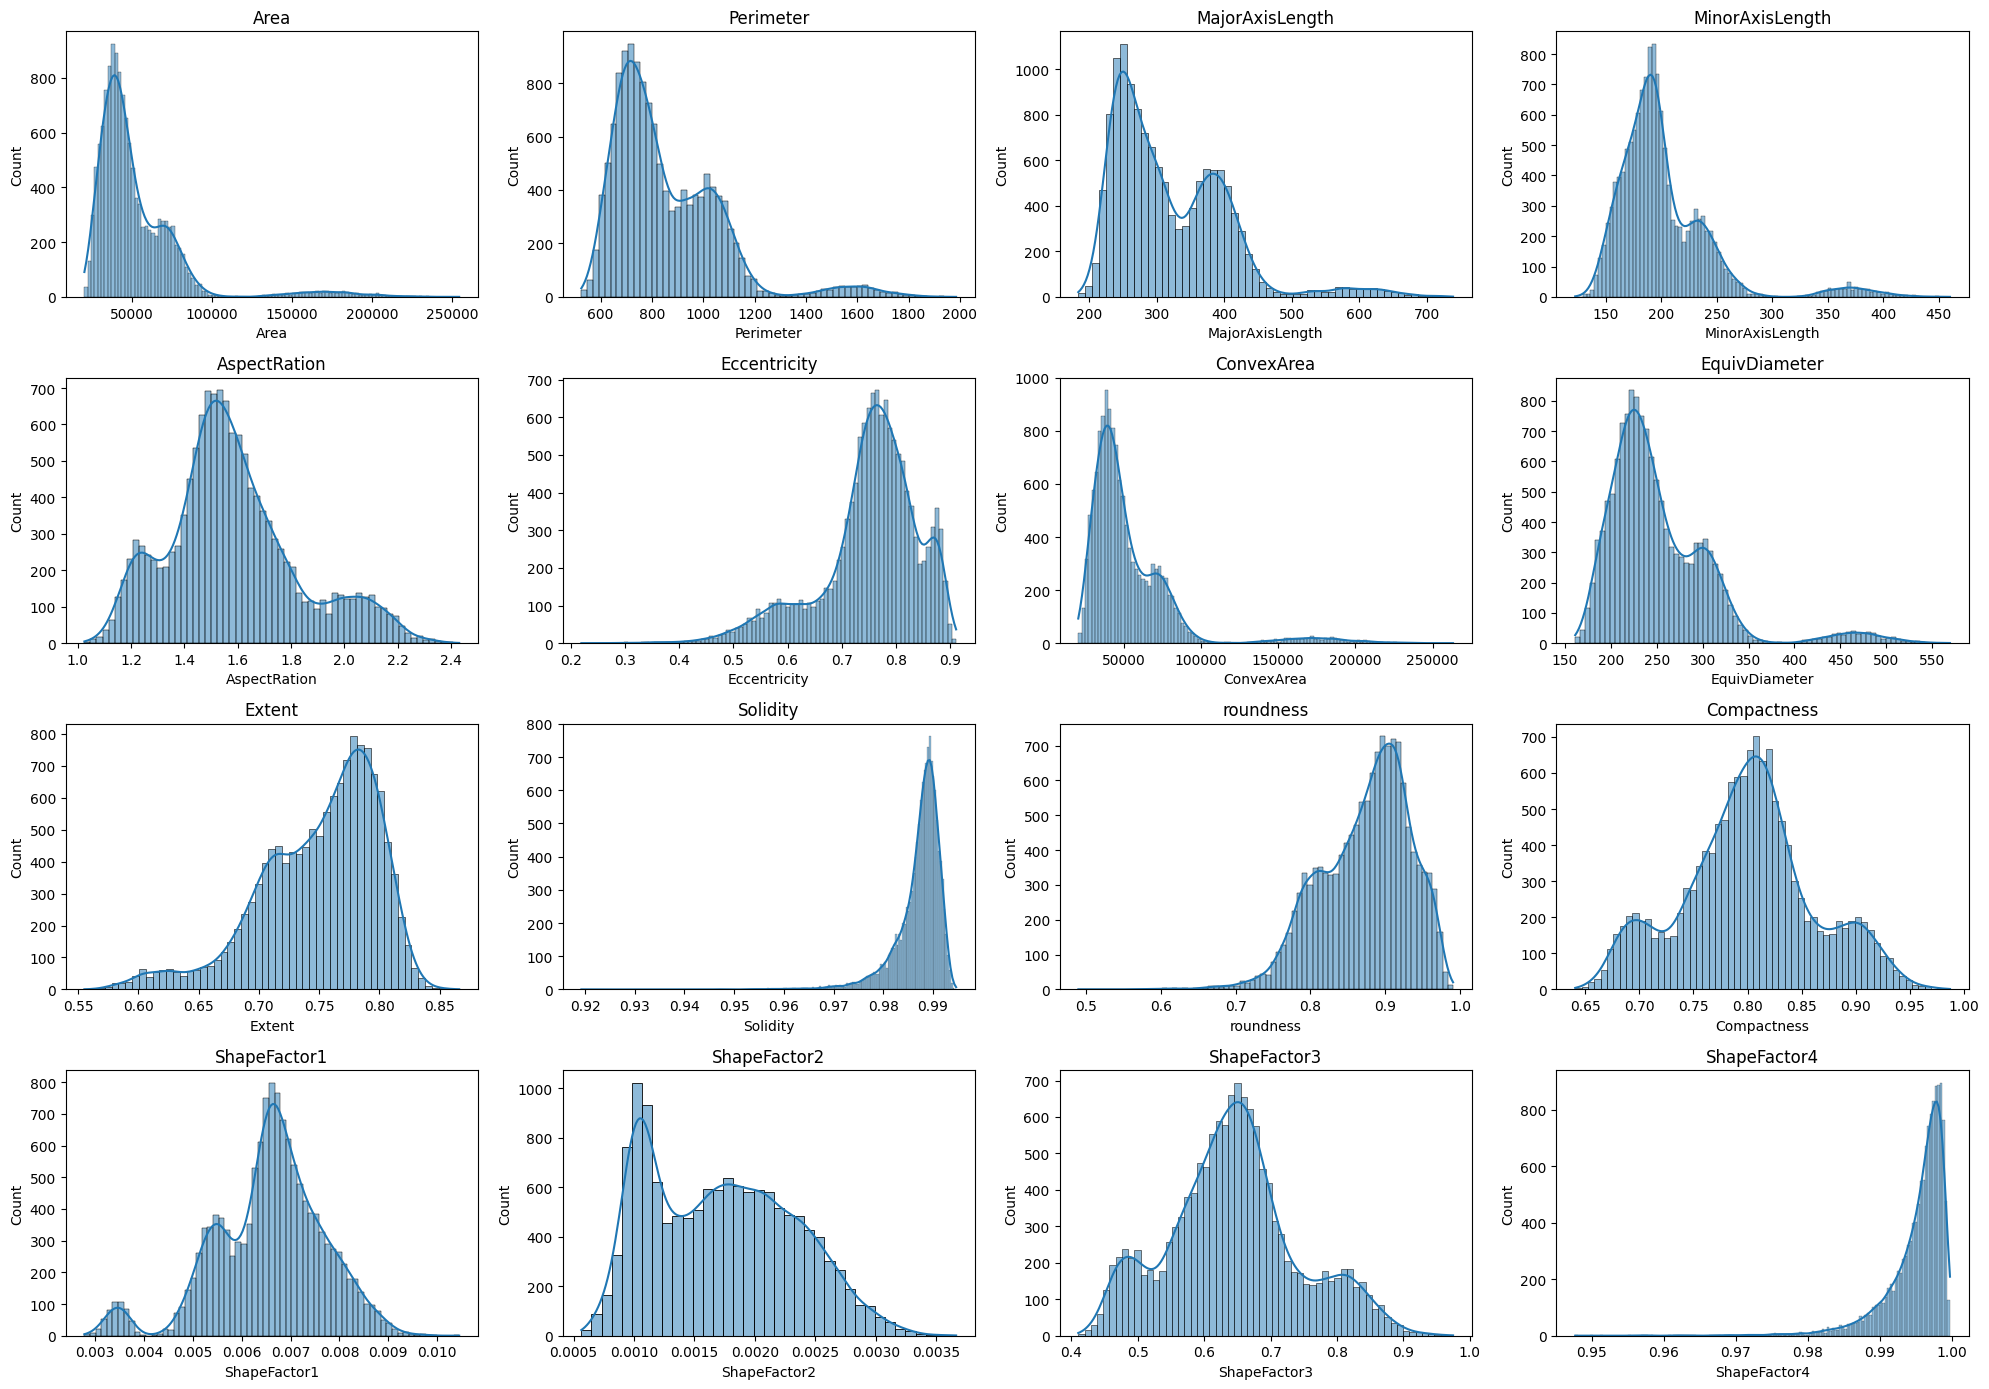

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(20, 14))
for a, c in zip(axes.flatten(), df.columns[:-1]):
    sns.histplot(df[c], kde=True, ax=a); a.set_title(c)
plt.tight_layout()
plt.show()

### 2.2 Boxplots of each feature

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(20, 14))
for a, c in zip(axes.flatten(), df.columns[:-1]):
    sns.boxplot(y=df[c], ax=a); a.set_title(c)
plt.tight_layout()
plt.show()

### 2.3 Feature vs Class (which features separate the classes?)

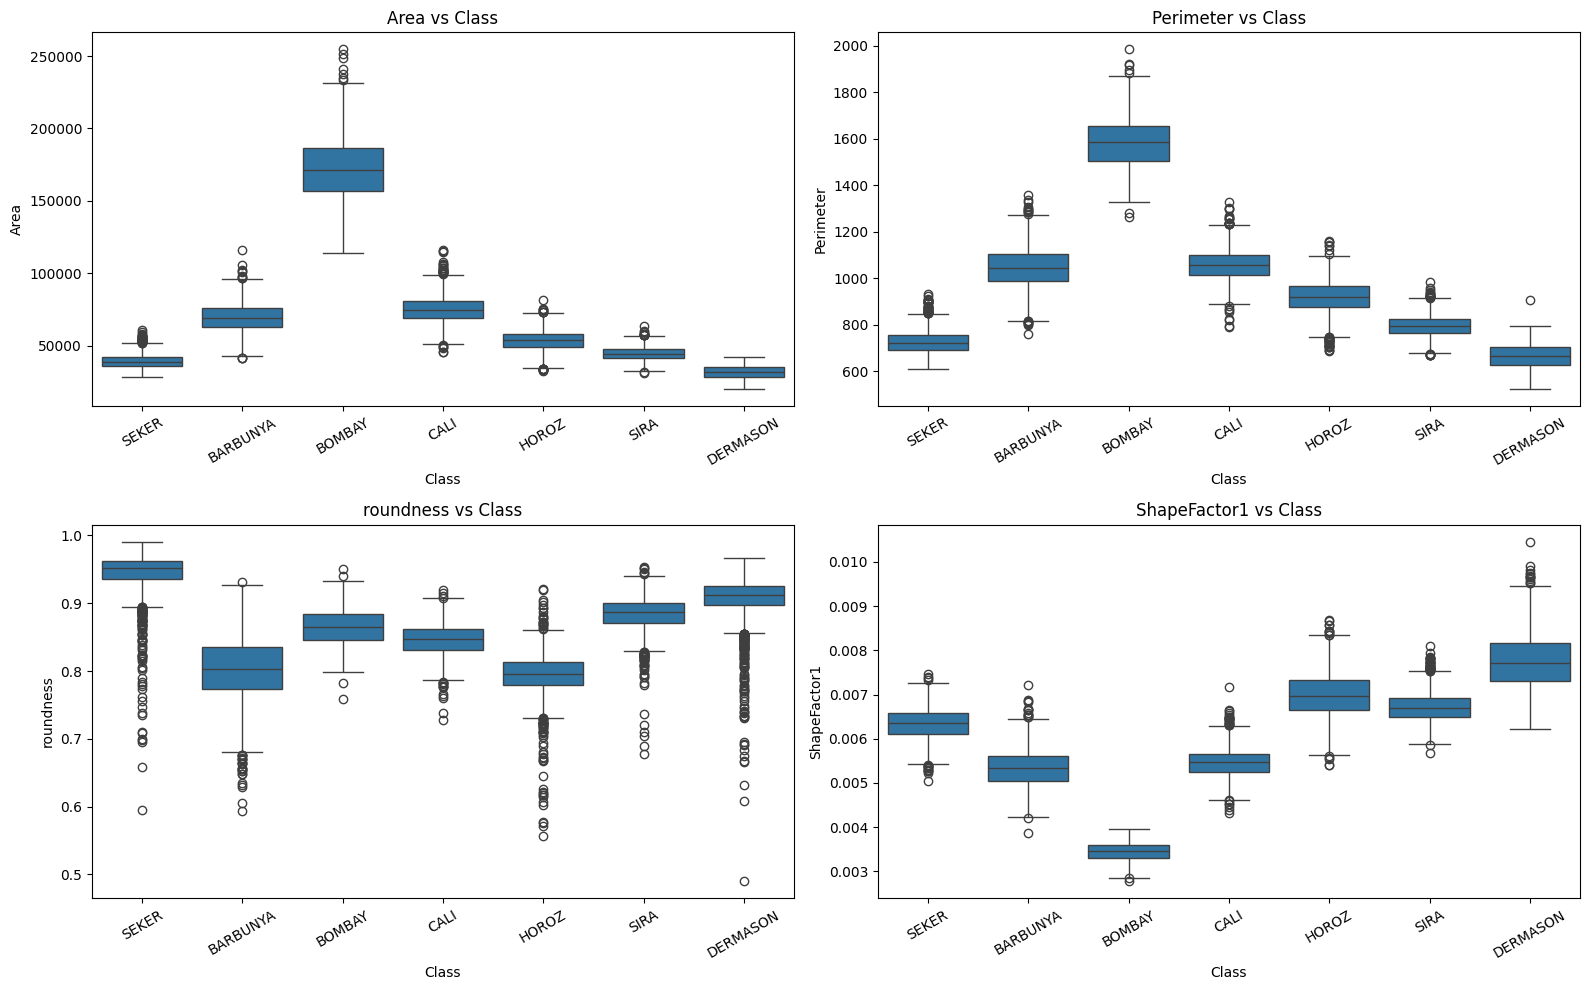

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for a, c in zip(axes.flatten(), ['Area', 'Perimeter', 'roundness', 'ShapeFactor1']):
    sns.boxplot(x='Class', y=c, data=df, ax=a); a.set_title(f'{c} vs Class')
    a.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### 2.4 Class Distribution (imbalance check)

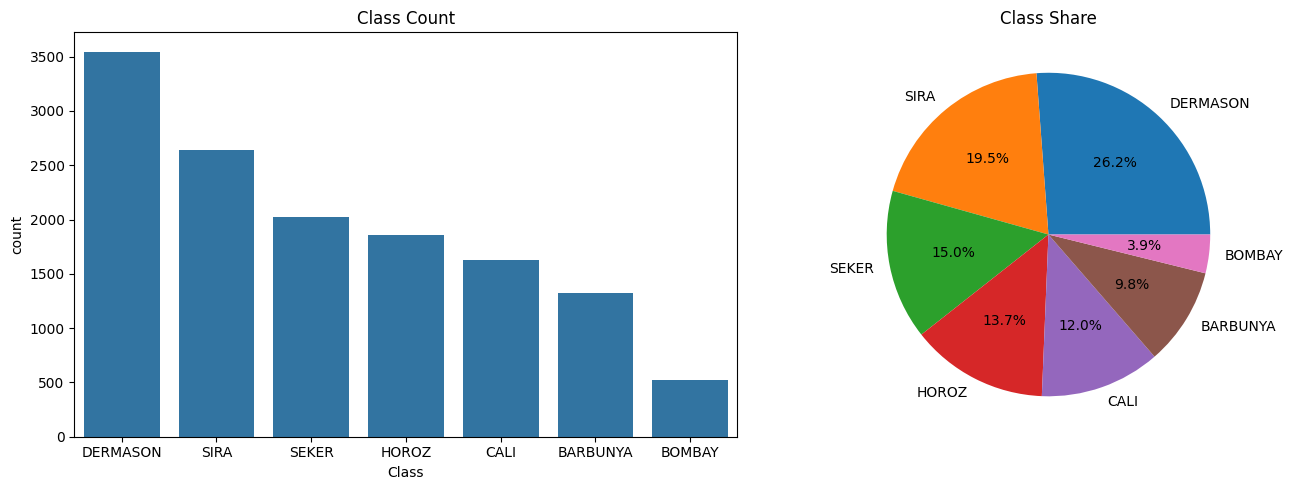

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Class
DERMASON    26.18
SIRA        19.46
SEKER       14.97
HOROZ       13.73
CALI        12.04
BARBUNYA     9.76
BOMBAY       3.85
Name: proportion, dtype: float64


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='Class', data=df, order=df['Class'].value_counts().index, ax=ax[0]); ax[0].set_title('Class Count')
df['Class'].value_counts().plot.pie(autopct='%1.1f%%', ax=ax[1]); ax[1].set_ylabel(''); ax[1].set_title('Class Share')
plt.tight_layout()
plt.show()

print(df['Class'].value_counts())
print()
print(df['Class'].value_counts(normalize=True).mul(100).round(2))

### 2.5 Correlation Heatmap

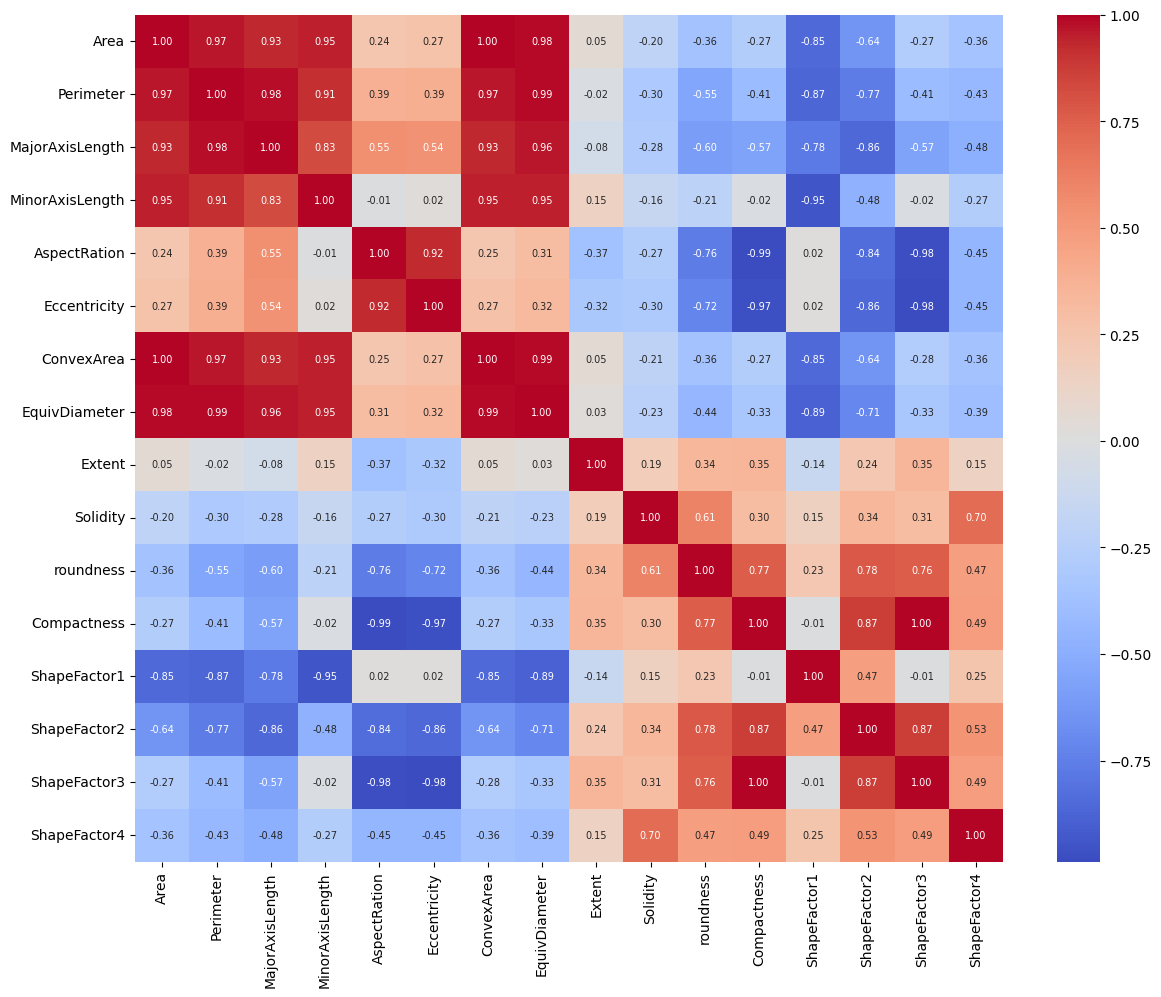

,Feature 1,Feature 2,Correlation
0,Area,Perimeter,0.967
1,Area,MinorAxisLength,0.952
2,Area,ConvexArea,1.000
3,Area,EquivDiameter,0.985
4,Perimeter,MajorAxisLength,0.978
5,Perimeter,ConvexArea,0.968
6,Perimeter,EquivDiameter,0.991
7,MajorAxisLength,EquivDiameter,0.962
8,MinorAxisLength,ConvexArea,0.952
9,AspectRation,Compactness,-0.988


In [12]:
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.show()

corr = df.corr(numeric_only=True)
high = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr.columns)
        for b in corr.columns[i+1:] if abs(corr.loc[a, b]) > 0.95]
pd.DataFrame(high, columns=['Feature 1', 'Feature 2', 'Correlation'])

### 2.6 Multivariate Relationships (Pairplot)

A pairplot of all 16 features would be unreadable and very slow, so we plot four representative features on a random sample of 2000 rows.

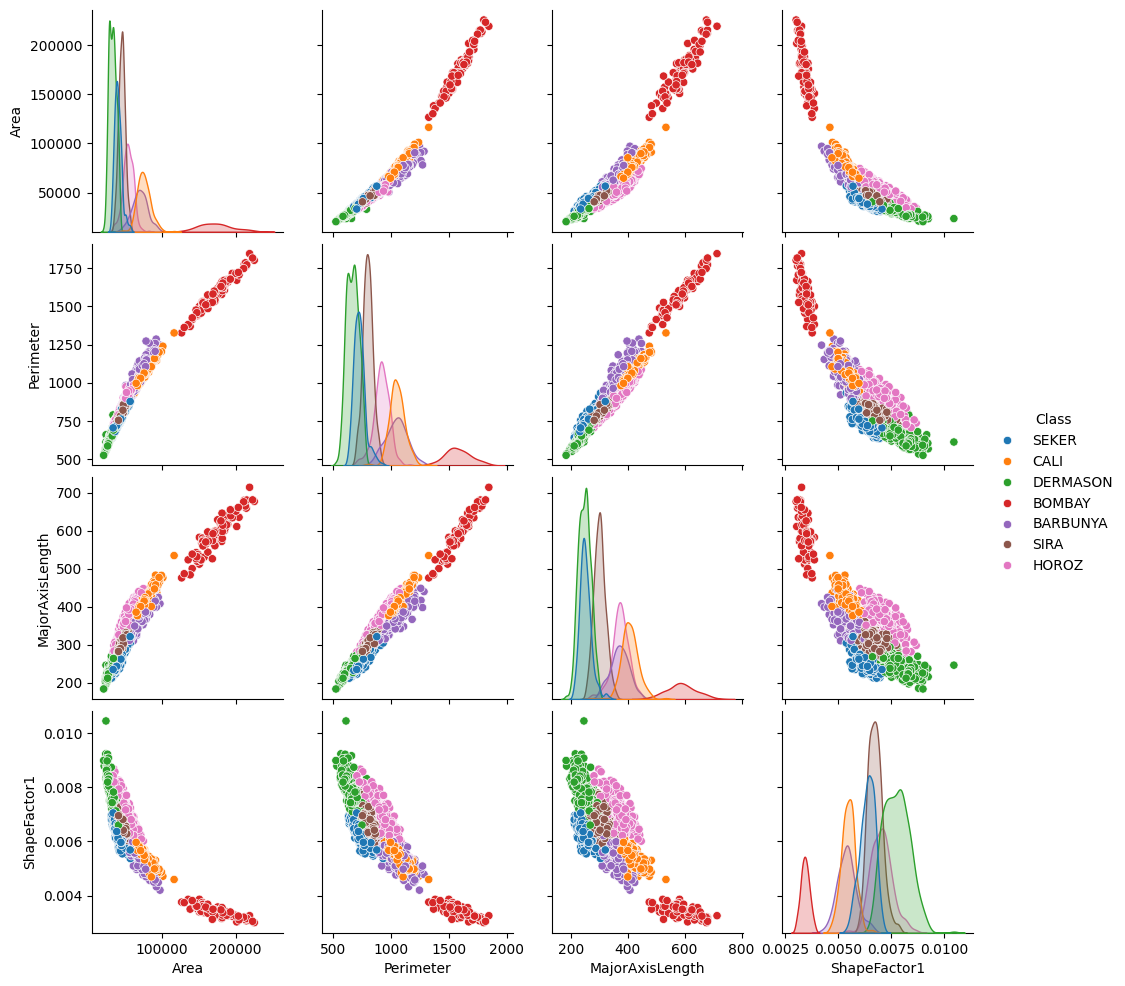

In [13]:
cols = ['Area', 'Perimeter', 'MajorAxisLength', 'ShapeFactor1', 'Class']
sns.pairplot(df[cols].sample(2000, random_state=42), hue='Class')
plt.show()

### 2.7 Skewness and Outlier Summary

In [14]:
skewness = df.skew(numeric_only=True)
def classify_skew(v):
    if v > 0.5: return 'Right-skewed'
    elif v < -0.5: return 'Left-skewed'
    return 'Approximately Symmetric'

skewness_result = pd.DataFrame({'Skewness': skewness, 'Distribution': skewness.apply(classify_skew)})
display(skewness_result.round(2))

rows = []
for c in df.columns[:-1]:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    low, up = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append([c, low, up, ((df[c] < low) | (df[c] > up)).sum()])
outlier_result = pd.DataFrame(rows, columns=['Column', 'Lower Bound', 'Upper Bound', 'Outliers'])
outlier_result

,Skewness,Distribution
Area,2.95,Right-skewed
Perimeter,1.63,Right-skewed
MajorAxisLength,1.37,Right-skewed
MinorAxisLength,2.23,Right-skewed
AspectRation,0.59,Right-skewed
Eccentricity,-1.06,Left-skewed
ConvexArea,2.94,Right-skewed
EquivDiameter,1.95,Right-skewed
Extent,-0.90,Left-skewed
Solidity,-2.55,Left-skewed


,Column,Lower Bound,Upper Bound,Outliers
0,Area,-1366.750000,99031.250000,551
1,Perimeter,292.355250,1388.021250,500
2,MajorAxisLength,68.248283,561.151012,379
3,MinorAxisLength,113.847788,279.283973,567
4,AspectRation,1.020780,2.113797,485
5,Eccentricity,0.573352,0.951463,833
6,ConvexArea,-1857.500000,100890.500000,549
7,EquivDiameter,117.992667,376.500961,526
8,Extent,0.616565,0.889019,271
9,Solidity,0.979168,0.996529,774


### 2.8 Key Findings

- **Class imbalance:** DERMASON is the largest class (about 26%) and BOMBAY the smallest (about 3.85%). Imbalance handling (class weights / SMOTE / resampling) is worth testing.
- **Size features** (`Area`, `Perimeter`, `ConvexArea`, `EquivDiameter`) separate classes well. BOMBAY beans are by far the largest, DERMASON and SEKER are the smallest.
- **Shape features** (`roundness`, `ShapeFactor1-4`, `Eccentricity`) help to separate classes of similar size.
- **Multicollinearity:** 15 feature pairs have an absolute correlation above 0.95 (for example `Area`-`ConvexArea` = 1.00 and `Compactness`-`ShapeFactor3` = 0.999). Feature scaling is necessary and linear models may be affected.
- **Skewness:** `Area`, `ConvexArea`, `MinorAxisLength`, `EquivDiameter`, `Perimeter` and `MajorAxisLength` are right-skewed; `Solidity`, `ShapeFactor4`, `Eccentricity`, `Extent` are left-skewed. This is treated in Task 4.
- **Outliers:** `Eccentricity`, `Solidity`, `ShapeFactor4` and `MinorAxisLength` contain the most IQR outliers; `ShapeFactor2` has none. Their nature is examined in Task 3.

## Task 3: Missing Values & Outlier Treatment

### 3.1 Missing values

In [15]:
print('Total missing values:', df.isnull().sum().sum())
print('Duplicates handled in Task 1.2, remaining duplicates:', df.duplicated().sum())

Total missing values: 0
Duplicates handled in Task 1.2, remaining duplicates: 0


### 3.2 Outlier detection (IQR method)

Before treating the outliers, we check **which class** they belong to. If they belong mostly to one class, they are genuine measurements of that bean type and not errors.

In [16]:
features = list(df.columns[:-1])

bounds = {}
for c in features:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    bounds[c] = (q1 - 1.5*iqr, q3 + 1.5*iqr)

rows = []
for c in features:
    lo, up = bounds[c]
    mask = (df[c] < lo) | (df[c] > up)
    n = mask.sum()
    top = df.loc[mask, 'Class'].value_counts()
    rows.append([c, n, round(100*n/len(df), 2),
                 top.index[0] if n else '-', round(100*top.iloc[0]/n, 1) if n else 0])
pd.DataFrame(rows, columns=['Feature', 'Outliers', 'Outlier %', 'Class with most outliers', '% of outliers in that class'])

,Feature,Outliers,Outlier %,Class with most outliers,% of outliers in that class
0,Area,551,4.07,BOMBAY,94.7
1,Perimeter,500,3.69,BOMBAY,100.0
2,MajorAxisLength,379,2.80,BOMBAY,100.0
3,MinorAxisLength,567,4.19,BOMBAY,92.1
4,AspectRation,485,3.58,HOROZ,100.0
5,Eccentricity,833,6.15,SEKER,98.2
6,ConvexArea,549,4.05,BOMBAY,95.1
7,EquivDiameter,526,3.88,BOMBAY,99.2
8,Extent,271,2.00,HOROZ,99.6
9,Solidity,774,5.72,CALI,32.9


### 3.3 Outlier treatment (IQR capping)

For most features the outliers are concentrated in one class (for example about 95% of the `Area` outliers and all `Perimeter` outliers are BOMBAY beans, which are naturally large; most `Eccentricity` outliers are SEKER). They are genuine measurements, not errors. Removing those rows would delete real data, especially from the minority class. So the rows are **kept** and the extreme values are **capped** at the IQR bounds (winsorization).

Shape (no rows removed): (13543, 17)


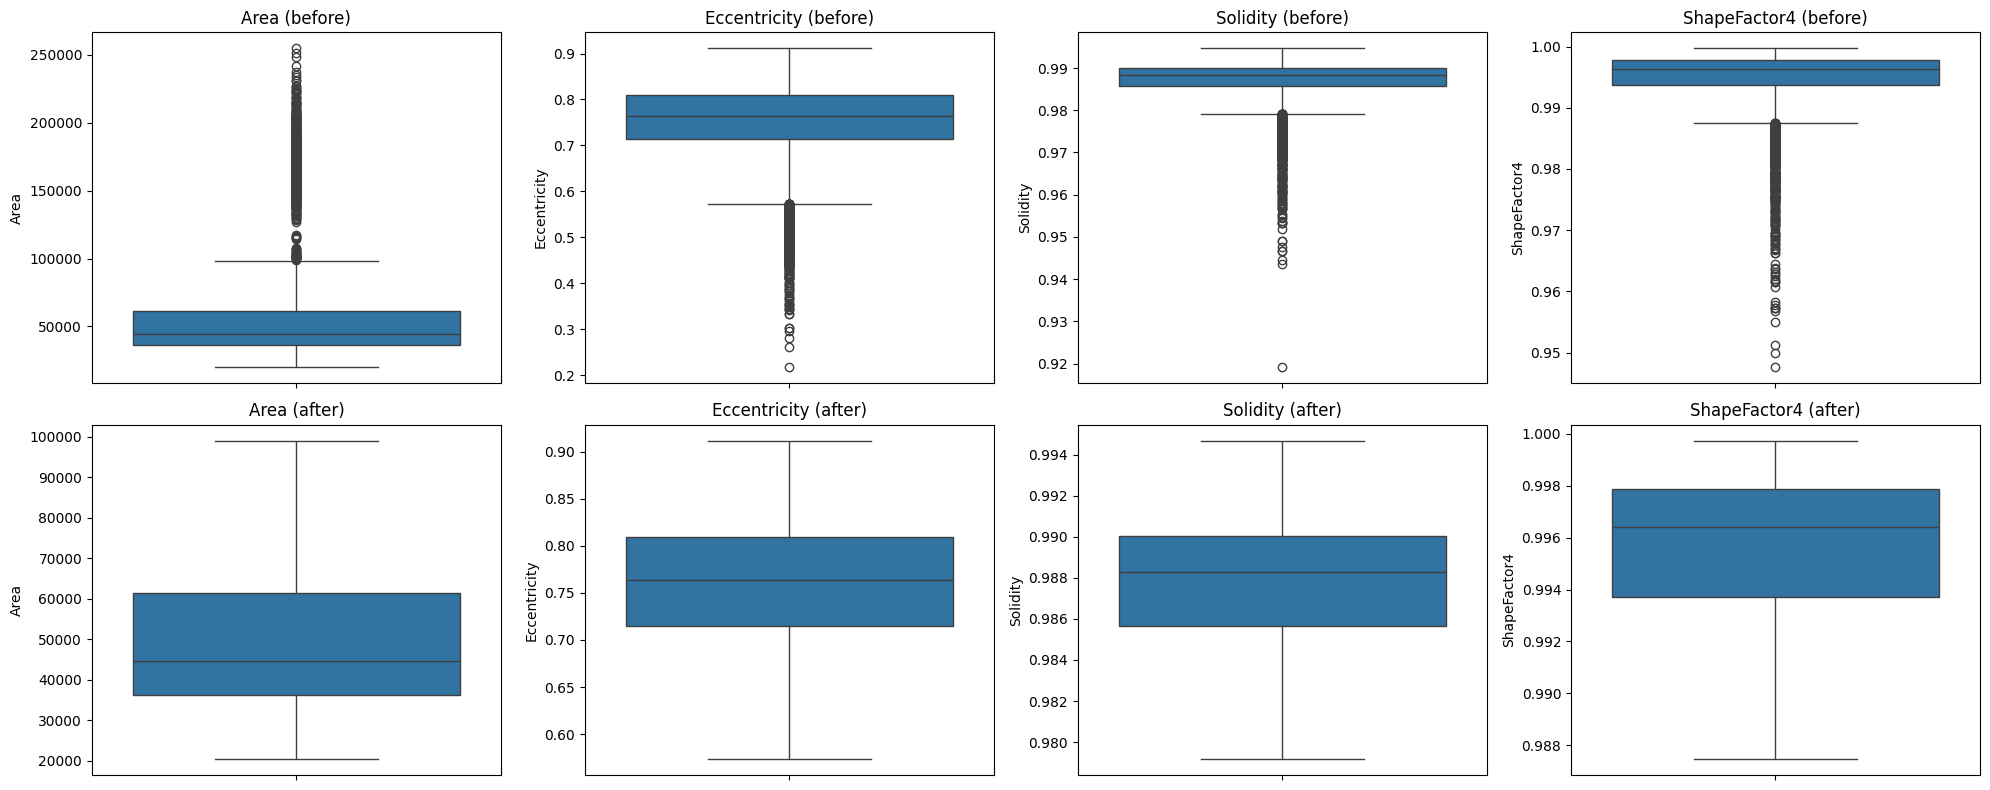

In [17]:
df_clip = df.copy()
for c in features:
    lo, up = bounds[c]
    df_clip[c] = df_clip[c].clip(lower=lo, upper=up)

print('Shape (no rows removed):', df_clip.shape)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, c in enumerate(['Area', 'Eccentricity', 'Solidity', 'ShapeFactor4']):
    sns.boxplot(y=df[c], ax=axes[0, j]); axes[0, j].set_title(f'{c} (before)')
    sns.boxplot(y=df_clip[c], ax=axes[1, j]); axes[1, j].set_title(f'{c} (after)')
plt.tight_layout()
plt.show()

In [18]:
rows = []
for c in features:
    q1, q3 = df_clip[c].quantile(0.25), df_clip[c].quantile(0.75)
    iqr = q3 - q1
    rows.append([c, ((df_clip[c] < q1 - 1.5*iqr) | (df_clip[c] > q3 + 1.5*iqr)).sum()])
pd.DataFrame(rows, columns=['Feature', 'Outliers after capping'])

,Feature,Outliers after capping
0,Area,0
1,Perimeter,0
2,MajorAxisLength,0
3,MinorAxisLength,0
4,AspectRation,0
5,Eccentricity,0
6,ConvexArea,0
7,EquivDiameter,0
8,Extent,0
9,Solidity,0


## Task 4: Feature Engineering & Preprocessing

Order followed: **skewness treatment → encoding → stratified train/test split → scaling.**

The skewness transformations are fixed functions applied row by row (they learn nothing from the data), so applying them before the split does not leak test information. The scaler learns the mean and standard deviation, so it is fitted on the training data only.

### 4.1 Skewness treatment

In [19]:
right_skew = ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'ConvexArea', 'EquivDiameter']

def fix_skew(data):
    data = data.copy()
    for c in right_skew:
        data[c] = np.log1p(data[c])
    for c in ['Eccentricity', 'Extent']:
        data[c] = data[c] ** 3
    for c in ['Solidity', 'ShapeFactor4']:
        data[c] = -np.log(1.001 - data[c].clip(upper=1.0))
    return data

df_t = df_clip.copy()
df_t[features] = fix_skew(df_clip[features])

skew_cmp = pd.DataFrame({'Skew before': df_clip[features].skew(), 'Skew after': df_t[features].skew()}).round(2)
skew_cmp

,Skew before,Skew after
Area,0.96,0.33
Perimeter,0.97,0.52
MajorAxisLength,0.98,0.48
MinorAxisLength,0.73,0.38
AspectRation,0.47,0.47
Eccentricity,-0.61,-0.12
ConvexArea,0.97,0.34
EquivDiameter,0.84,0.45
Extent,-0.78,-0.48
Solidity,-0.84,-0.34


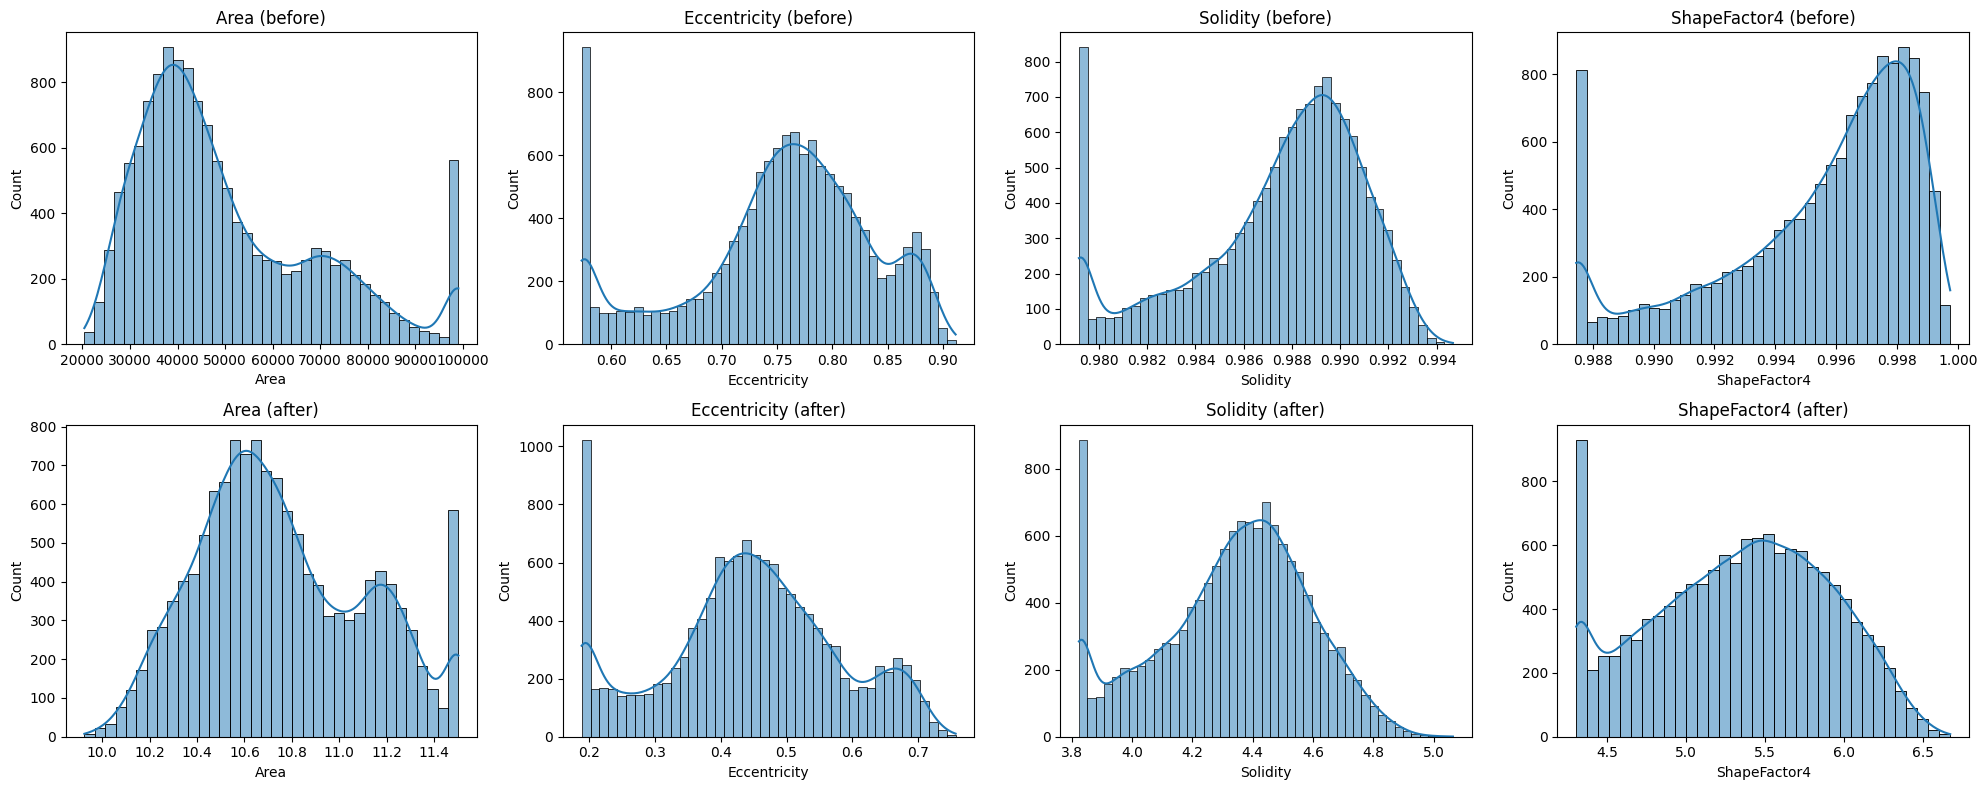

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, c in enumerate(['Area', 'Eccentricity', 'Solidity', 'ShapeFactor4']):
    sns.histplot(df_clip[c], kde=True, ax=axes[0, j]); axes[0, j].set_title(f'{c} (before)')
    sns.histplot(df_t[c], kde=True, ax=axes[1, j]); axes[1, j].set_title(f'{c} (after)')
plt.tight_layout()
plt.show()

### 4.2 Encoding the target

All input features are numeric. Only the target `Class` is text, so it is label-encoded.

In [21]:
le = LabelEncoder()
X = df_t[features]
y = le.fit_transform(df_t['Class'])
print(dict(zip(le.classes_, range(len(le.classes_)))))

{'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}


### 4.3 Stratified train/test split (80/20)

In [22]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

split_check = pd.DataFrame({'Train %': pd.Series(Y_train).map(dict(enumerate(le.classes_))).value_counts(normalize=True).mul(100),
                            'Test %':  pd.Series(Y_test).map(dict(enumerate(le.classes_))).value_counts(normalize=True).mul(100)}).round(2)
split_check

Train: (10834, 16)  Test: (2709, 16)


,Train %,Test %
DERMASON,26.19,26.17
SIRA,19.47,19.45
SEKER,14.96,14.99
HOROZ,13.73,13.73
CALI,12.04,12.03
BARBUNYA,9.76,9.78
BOMBAY,3.86,3.84


### 4.4 Feature scaling (StandardScaler)

In [23]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print('Train mean ~', X_train_s.mean().round(3), ' Train std ~', X_train_s.std().round(3))

Train mean ~ 0.0  Train std ~ 1.0


**Summary of preprocessing:** extreme values were capped (Task 3); skewed features were transformed with log / power / reflected-log; the target was label-encoded; a stratified 80/20 split keeps the class ratios identical in both sets; features were standardised using statistics from the training set only.

## Task 5: Model Building - Multiple Classifiers

Eleven classifiers are trained on the scaled training set: linear, tree-based, distance-based, probabilistic, boosting/bagging ensembles and a voting ensemble. Each model is also evaluated with **5-fold stratified cross-validation** on the training data to check how stable its performance is.

- **F1 Score** reported everywhere is the **macro average** (every class counts equally), which is the fair choice for an imbalanced dataset.
- **Overfitting rule:** a model is flagged `Y` when *train accuracy - test accuracy > 0.05*.

In [24]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def summarise(name, model, cv_acc, cv_f1):
    tr_pred, te_pred = model.predict(X_train_s), model.predict(X_test_s)
    tr_acc, te_acc = accuracy_score(Y_train, tr_pred), accuracy_score(Y_test, te_pred)
    return {'Model': name,
            'CV Accuracy': cv_acc, 'CV F1': cv_f1,
            'Train Accuracy': tr_acc, 'Test Accuracy': te_acc,
            'F1 Score': f1_score(Y_test, te_pred, average='macro'),
            'Overfitting (Y/N)': 'Y' if tr_acc - te_acc > 0.05 else 'N'}

models = {
    'Logistic Regression': LogisticRegression(max_iter=3000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(random_state=42, n_jobs=-1),
    'KNN':                 KNeighborsClassifier(),
    'SVM':                 SVC(random_state=42),
    'Naive Bayes':         GaussianNB(),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=42),
    'AdaBoost':            AdaBoostClassifier(random_state=42),
    'XGBoost':             XGBClassifier(random_state=42, eval_metric='mlogloss', n_jobs=-1),
    'Bagging':             BaggingClassifier(random_state=42, n_jobs=-1),
}

fitted, rows = {}, []
for name, m in models.items():
    cv = cross_validate(m, X_train_s, Y_train, cv=skf, scoring={'acc': 'accuracy', 'f1': 'f1_macro'}, n_jobs=-1)
    m.fit(X_train_s, Y_train)
    fitted[name] = m
    rows.append(summarise(name, m, cv['test_acc'].mean(), cv['test_f1'].mean()))
    print(f'{name:22s}')

baseline_df = pd.DataFrame(rows)
baseline_df.sort_values('CV F1', ascending=False).reset_index(drop=True).round(4)

Logistic Regression   
Decision Tree         
Random Forest         
KNN                   
SVM                   
Naive Bayes           
Gradient Boosting     
AdaBoost              
XGBoost               
Bagging               


,Model,CV Accuracy,CV F1,Train Accuracy,Test Accuracy,F1 Score,Overfitting (Y/N)
0,SVM,0.9305,0.9424,0.9340,0.9228,0.9349,N
1,XGBoost,0.9283,0.9401,1.0000,0.9173,0.9284,Y
2,Gradient Boosting,0.9275,0.9387,0.9632,0.9188,0.9307,N
3,Logistic Regression,0.9254,0.9382,0.9269,0.9210,0.9315,N
4,Random Forest,0.9232,0.9345,1.0000,0.9217,0.9328,Y
5,KNN,0.9197,0.9326,0.9421,0.9062,0.9192,N
6,Bagging,0.9189,0.9301,0.9945,0.9110,0.9240,Y
7,Decision Tree,0.8974,0.9120,1.0000,0.8970,0.9117,Y
8,Naive Bayes,0.8975,0.9083,0.8971,0.9011,0.9110,N
9,AdaBoost,0.7931,0.6902,0.7789,0.7697,0.6208,N


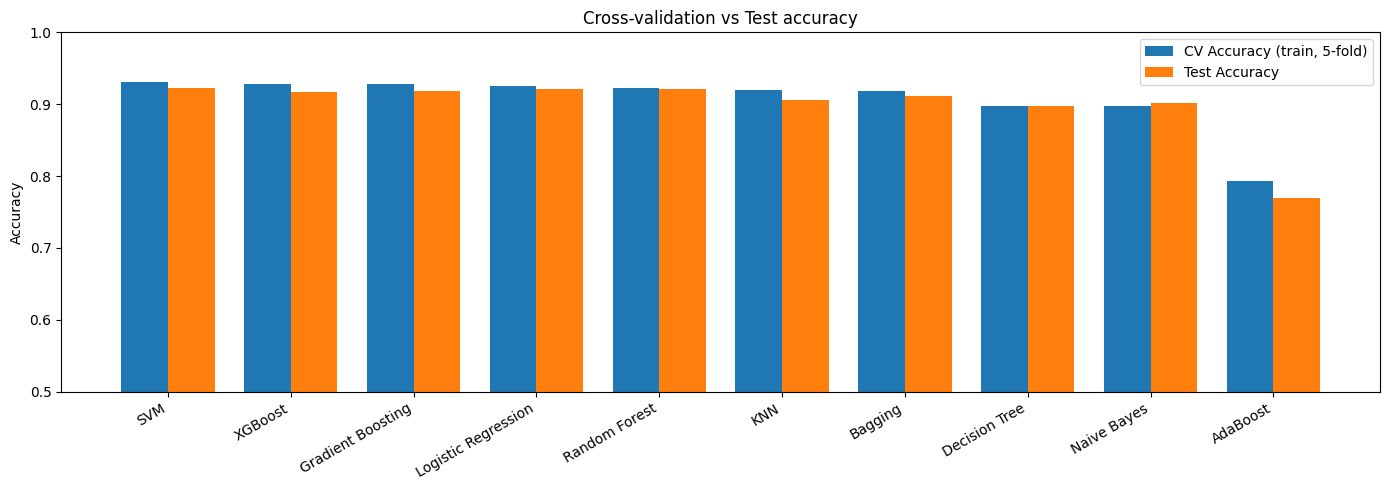

In [25]:
plot_df = baseline_df.sort_values('CV F1', ascending=False)
x = np.arange(len(plot_df)); w = 0.38
plt.figure(figsize=(14, 5))
plt.bar(x - w/2, plot_df['CV Accuracy'], w, label='CV Accuracy (train, 5-fold)')
plt.bar(x + w/2, plot_df['Test Accuracy'], w, label='Test Accuracy')
plt.xticks(x, plot_df['Model'], rotation=30, ha='right')
plt.ylim(0.5, 1.0); plt.ylabel('Accuracy'); plt.title('Cross-validation vs Test accuracy'); plt.legend()
plt.tight_layout(); plt.show()

**Cross-validation check:** the cross-validation accuracy and the test accuracy of each model are within about 1 to 1.5 percentage points of each other (AdaBoost about 2), so the test score is not a lucky split and the models generalise consistently. Deep tree models (Decision Tree, Random Forest, XGBoost, Bagging) reach 100% or near 100% training accuracy but not on unseen data, which Task 7 examines. AdaBoost with its default shallow stumps underfits (about 77% accuracy).

## Task 6: Handling Class Imbalance

BOMBAY (3.85%) is the minority class. Four techniques are compared against the original (no handling) setting on three representative models (Logistic Regression, SVM, Random Forest):

1. **Class weighting** (`class_weight='balanced'`)
2. **SMOTE** (synthetic minority over-sampling)
3. **Random over-sampling**
4. **Random under-sampling**

Resampling is applied **only to the training set**; the test set is never touched.

In [26]:
def make_model(name, balanced=False):
    cw = 'balanced' if balanced else None
    if name == 'Logistic Regression': return LogisticRegression(max_iter=3000, class_weight=cw, random_state=42)
    if name == 'SVM':                 return SVC(class_weight=cw, random_state=42)
    if name == 'Random Forest':       return RandomForestClassifier(class_weight=cw, random_state=42, n_jobs=-1)

samplers = {'No handling': None, 'Class weight': 'cw',
            'SMOTE': SMOTE(random_state=42),
            'Random Oversampling': RandomOverSampler(random_state=42),
            'Random Undersampling': RandomUnderSampler(random_state=42)}

min_idx = list(le.classes_).index('BOMBAY')
rows = []
for mname in ['Logistic Regression', 'SVM', 'Random Forest']:
    for sname, s in samplers.items():
        if s is None:
            Xr, yr, m = X_train_s, Y_train, make_model(mname)
        elif s == 'cw':
            Xr, yr, m = X_train_s, Y_train, make_model(mname, balanced=True)
        else:
            Xr, yr = s.fit_resample(X_train_s, Y_train); m = make_model(mname)
        m.fit(Xr, yr)
        pred = m.predict(X_test_s)
        rows.append({'Model': mname, 'Technique': sname,
                     'Test Accuracy': accuracy_score(Y_test, pred),
                     'Macro F1': f1_score(Y_test, pred, average='macro'),
                     'BOMBAY F1': f1_score(Y_test, pred, average=None)[min_idx],
                     'BOMBAY Recall': (pred[Y_test == min_idx] == min_idx).mean()})

imb_df = pd.DataFrame(rows)
imb_df.round(4)

,Model,Technique,Test Accuracy,Macro F1,BOMBAY F1,BOMBAY Recall
0,Logistic Regression,No handling,0.9210,0.9315,1.0,1.0
1,Logistic Regression,Class weight,0.9147,0.9267,1.0,1.0
2,Logistic Regression,SMOTE,0.9166,0.9287,1.0,1.0
3,Logistic Regression,Random Oversampling,0.9166,0.9283,1.0,1.0
4,Logistic Regression,Random Undersampling,0.9129,0.9253,1.0,1.0
5,SVM,No handling,0.9228,0.9349,1.0,1.0
6,SVM,Class weight,0.9247,0.9360,1.0,1.0
7,SVM,SMOTE,0.9236,0.9347,1.0,1.0
8,SVM,Random Oversampling,0.9254,0.9363,1.0,1.0
9,SVM,Random Undersampling,0.9147,0.9276,1.0,1.0


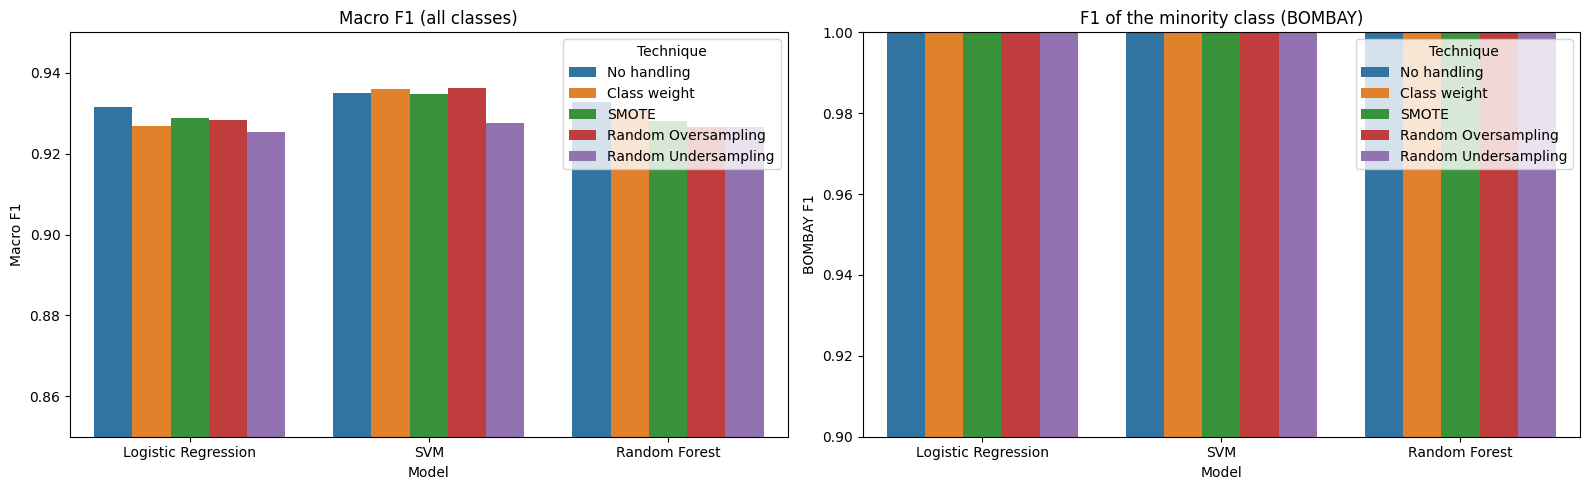

Best technique per model (by macro F1) vs no handling:
  Logistic Regression  -> No handling            macro F1 0.9315  (baseline 0.9315, change +0.0000)
  Random Forest        -> No handling            macro F1 0.9328  (baseline 0.9328, change +0.0000)
  SVM                  -> Random Oversampling    macro F1 0.9363  (baseline 0.9349, change +0.0014)


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=imb_df, x='Model', y='Macro F1', hue='Technique', ax=ax[0]); ax[0].set_ylim(0.85, 0.95); ax[0].set_title('Macro F1 (all classes)')
sns.barplot(data=imb_df, x='Model', y='BOMBAY F1', hue='Technique', ax=ax[1]); ax[1].set_ylim(0.9, 1.0); ax[1].set_title('F1 of the minority class (BOMBAY)')
plt.tight_layout(); plt.show()

base = imb_df[imb_df['Technique'] == 'No handling'].set_index('Model')['Macro F1']
best = imb_df.loc[imb_df.groupby('Model')['Macro F1'].idxmax()].set_index('Model')
print('Best technique per model (by macro F1) vs no handling:')
for m in best.index:
    print(f"  {m:20s} -> {best.loc[m, 'Technique']:22s} macro F1 {best.loc[m, 'Macro F1']:.4f}  (baseline {base[m]:.4f}, change {best.loc[m, 'Macro F1'] - base[m]:+.4f})")

**Observation (Task 6):**
- BOMBAY, the minority class (3.85%), is classified **perfectly (F1 = 1.00, recall = 1.00) with every technique, including no handling at all**. BOMBAY beans are much larger than all other beans, so the models separate them easily even with few samples.
- Class weights, SMOTE and random over/under-sampling changed the macro-F1 by at most about 0.006 in either direction. Logistic Regression and Random Forest were best with no handling; SVM gained only +0.0014 with random over-sampling, a difference too small to be meaningful. Under-sampling lowered the accuracy of all three models because it throws training data away.
- **Decision:** class imbalance is not a real problem for this dataset, so the final model is trained on the original (non-resampled) data. The classes that are actually hard to separate are SIRA and DERMASON, because their shape features overlap, not because of imbalance (see Task 7).

## Task 7: Model Evaluation & Overfitting Check

### 7.1 Train vs Test accuracy (overfitting check)

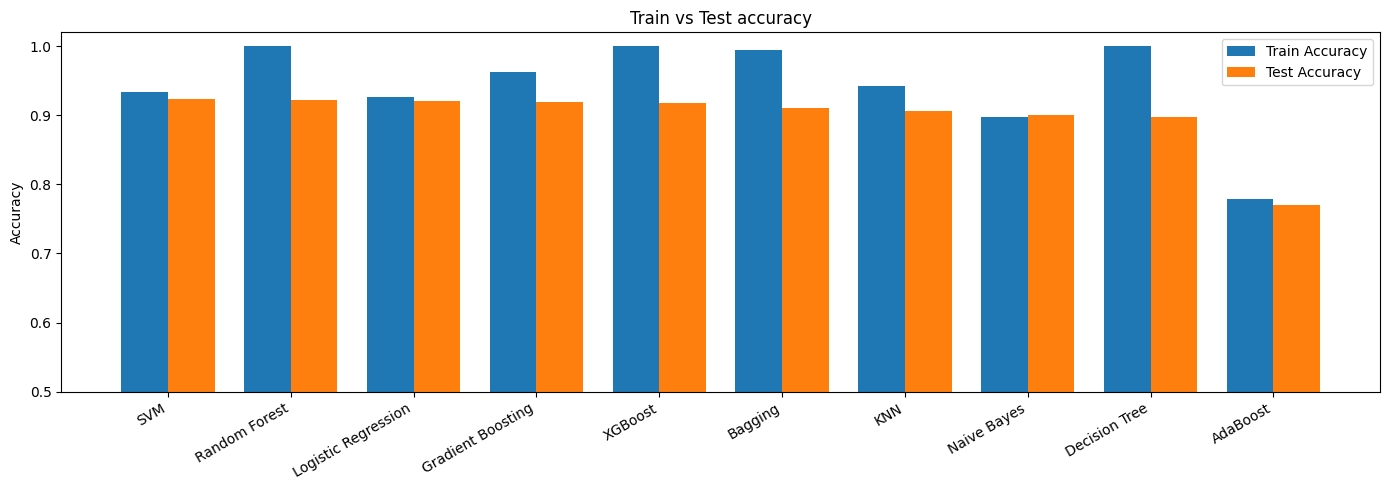

,Model,Train Accuracy,Test Accuracy,Overfitting (Y/N),Gap
0,Decision Tree,1.0000,0.8970,Y,0.1030
1,Bagging,0.9945,0.9110,Y,0.0834
2,XGBoost,1.0000,0.9173,Y,0.0827
3,Random Forest,1.0000,0.9217,Y,0.0783
4,Gradient Boosting,0.9632,0.9188,N,0.0444
5,KNN,0.9421,0.9062,N,0.0359
6,SVM,0.9340,0.9228,N,0.0112
7,AdaBoost,0.7789,0.7697,N,0.0093
8,Logistic Regression,0.9269,0.9210,N,0.0059
9,Naive Bayes,0.8971,0.9011,N,-0.0040


In [28]:
plot_df = baseline_df.sort_values('Test Accuracy', ascending=False)
x = np.arange(len(plot_df)); w = 0.38
plt.figure(figsize=(14, 5))
plt.bar(x - w/2, plot_df['Train Accuracy'], w, label='Train Accuracy')
plt.bar(x + w/2, plot_df['Test Accuracy'], w, label='Test Accuracy')
plt.xticks(x, plot_df['Model'], rotation=30, ha='right')
plt.ylim(0.5, 1.02); plt.ylabel('Accuracy'); plt.title('Train vs Test accuracy'); plt.legend()
plt.tight_layout(); plt.show()

gap = baseline_df[['Model', 'Train Accuracy', 'Test Accuracy', 'Overfitting (Y/N)']].copy()
gap['Gap'] = gap['Train Accuracy'] - gap['Test Accuracy']
gap.sort_values('Gap', ascending=False).round(4).reset_index(drop=True)

### 7.2 Precision, Recall, F1 (per class) and Confusion Matrix

The helper below is reused later for the final tuned model. Here it is applied to the best baseline model (highest cross-validation F1).

===== SVM =====
Test Accuracy : 0.9228
Macro F1      : 0.9349

              precision    recall  f1-score   support

    BARBUNYA      0.938     0.909     0.923       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.922     0.948     0.935       326
    DERMASON      0.912     0.920     0.916       709
       HOROZ      0.967     0.938     0.952       372
       SEKER      0.944     0.958     0.951       406
        SIRA      0.869     0.865     0.867       527

    accuracy                          0.923      2709
   macro avg      0.936     0.934     0.935      2709
weighted avg      0.923     0.923     0.923      2709



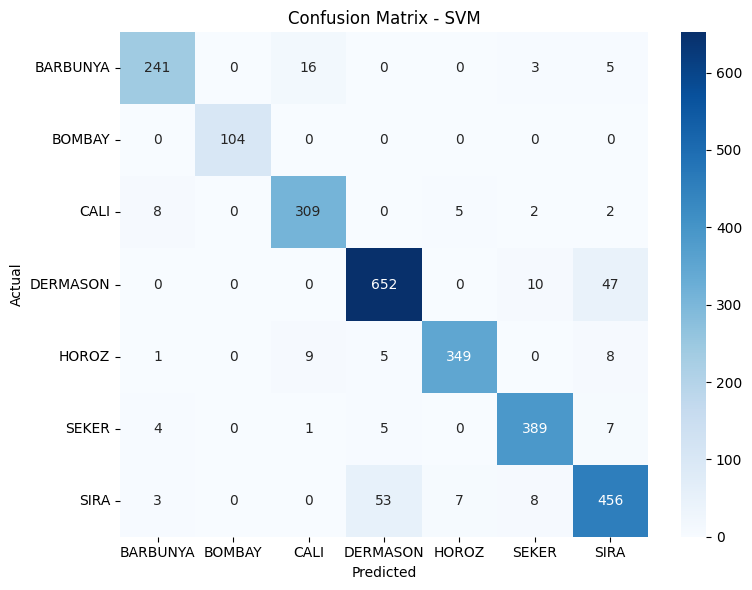

In [29]:
def evaluate(model, name):
    pred = model.predict(X_test_s)
    print(f'===== {name} =====')
    print(f'Test Accuracy : {accuracy_score(Y_test, pred):.4f}')
    print(f"Macro F1      : {f1_score(Y_test, pred, average='macro'):.4f}\n")
    print(classification_report(Y_test, pred, target_names=le.classes_, digits=3))
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_matrix(Y_test, pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'Confusion Matrix - {name}')
    plt.tight_layout(); plt.show()

best_base = baseline_df.sort_values('CV F1', ascending=False).iloc[0]['Model']
evaluate(fitted[best_base], best_base)

**Observations (Task 7):**
- **Overfitting:** Decision Tree (gap 0.103), Bagging (0.083), XGBoost (0.083) and Random Forest (0.078) are flagged `Y`. They grow deep trees that memorise the training set (train accuracy 99-100%) while the test accuracy is only 0.90-0.92. SVM, Logistic Regression, Voting, KNN, Gradient Boosting and Naive Bayes have gaps below 0.05 and generalise well.
- **AdaBoost underfits:** with the default shallow decision stumps both its train (0.78) and test (0.77) accuracy are low.
- **Best baseline model (SVM):** test accuracy 0.923 and macro-F1 0.935. BOMBAY is perfect (precision = recall = 1.00); the weakest class is SIRA (F1 0.867), followed by DERMASON (0.916) and BARBUNYA (0.923).
- Most errors in the confusion matrix are between **SIRA and DERMASON** and between **BARBUNYA and CALI**, which are the classes with similar shapes and sizes.

## Task 8: Hyperparameter Tuning

`RandomizedSearchCV` (3-fold stratified CV, macro-F1 as the score) is used to tune the **top-performing tunable models** from the baseline ranking. After tuning, each tuned model is cross-validated again with the same 5-fold setup as Task 5 so that all numbers are directly comparable.

In [31]:
param_space = {
    'SVM': (SVC(random_state=42),
            {'C': [1, 5, 10, 20, 50, 100], 'gamma': ['scale', 0.003, 0.01, 0.03, 0.1], 'kernel': ['rbf']}),
    'Logistic Regression': (LogisticRegression(max_iter=5000, random_state=42),
            {'C': [0.01, 0.1, 1, 10, 100, 1000]}),
    'Random Forest': (RandomForestClassifier(random_state=42, n_jobs=-1),
            {'n_estimators': [100, 200, 300], 'max_depth': [8, 12, 16, None],
             'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 'log2']}),
    'XGBoost': (XGBClassifier(random_state=42, eval_metric='mlogloss', n_jobs=-1),
            {'n_estimators': [100, 200, 300], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [2, 3, 4, 5],
             'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.7, 0.85, 1.0]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=42),
            {'n_estimators': [100, 150], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3], 'subsample': [0.8, 1.0]}),
    'KNN': (KNeighborsClassifier(),
            {'n_neighbors': [3, 5, 7, 9, 11, 15], 'weights': ['uniform', 'distance'], 'p': [1, 2]}),
}

ranking = baseline_df.sort_values('CV F1', ascending=False)['Model'].tolist()
to_tune = [m for m in ranking if m in param_space][:4]
print('Models selected for tuning (top tunable models by CV F1):', to_tune)

Models selected for tuning (top tunable models by CV F1): ['SVM', 'XGBoost', 'Gradient Boosting', 'Logistic Regression']


In [32]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
tuned, tuned_rows, best_params = {}, [], {}

for name in to_tune:
    est, grid = param_space[name]
    n_comb = int(np.prod([len(v) for v in grid.values()]))
    search = RandomizedSearchCV(est, grid, n_iter=min(10, n_comb), cv=cv3, scoring='f1_macro',
                                random_state=42, n_jobs=-1)
    search.fit(X_train_s, Y_train)
    best = search.best_estimator_
    cv = cross_validate(best, X_train_s, Y_train, cv=skf, scoring={'acc': 'accuracy', 'f1': 'f1_macro'}, n_jobs=-1)
    tuned[name + ' (Tuned)'] = best
    best_params[name] = search.best_params_
    tuned_rows.append(summarise(name + ' (Tuned)', best, cv['test_acc'].mean(), cv['test_f1'].mean()))
    print(f'{name:20s} best params: {search.best_params_}')

tuned_df = pd.DataFrame(tuned_rows)

SVM                  best params: {'kernel': 'rbf', 'gamma': 0.03, 'C': 100}
XGBoost              best params: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.85}
Gradient Boosting    best params: {'subsample': 1.0, 'n_estimators': 150, 'max_depth': 3, 'learning_rate': 0.1}
Logistic Regression  best params: {'C': 100}


In [33]:
imp = []
for name in to_tune:
    b = baseline_df[baseline_df['Model'] == name].iloc[0]
    t = tuned_df[tuned_df['Model'] == name + ' (Tuned)'].iloc[0]
    imp.append({'Model': name, 'Best Parameters': best_params[name],
                'CV F1 before': b['CV F1'], 'CV F1 after': t['CV F1'],
                'Test Acc before': b['Test Accuracy'], 'Test Acc after': t['Test Accuracy'],
                'Test F1 before': b['F1 Score'], 'Test F1 after': t['F1 Score'],
                'Test F1 change': t['F1 Score'] - b['F1 Score']})
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(imp).round(4)

,Model,Best Parameters,CV F1 before,CV F1 after,Test Acc before,Test Acc after,Test F1 before,Test F1 after,Test F1 change
0,SVM,"{'kernel': 'rbf', 'gamma': 0.03, 'C': 100}",0.9424,0.9424,0.9228,0.9228,0.9349,0.9339,-0.0010
1,XGBoost,"{'subsample': 0.7, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.85}",0.9401,0.9411,0.9173,0.9195,0.9284,0.9310,0.0025
2,Gradient Boosting,"{'subsample': 1.0, 'n_estimators': 150, 'max_depth': 3, 'learning_rate': 0.1}",0.9387,0.9401,0.9188,0.9177,0.9307,0.9294,-0.0013
3,Logistic Regression,{'C': 100},0.9382,0.9391,0.9210,0.9236,0.9315,0.9344,0.0029


**Observations (Task 8):**
- Tuning changed the **test macro-F1 only slightly (between -0.0013 and +0.0029)**. SVM (best parameters `C=100, gamma=0.03`) kept the same test accuracy of 0.9228; XGBoost and Logistic Regression improved a little; Gradient Boosting scored slightly lower on the test set and became more overfit.
- Tuning did reduce overfitting of XGBoost: its train accuracy dropped from 1.00 to 0.95 while its test accuracy rose from 0.9173 to 0.9195.
- The default models were already close to what these 16 features allow (about 92-93% accuracy). Larger gains would need more informative features rather than more tuning.

## Task 9: Model Comparison Table

All baseline and tuned models in the format requested in the assignment. The **best model is chosen using cross-validation F1 on the training data** (not the test set), so the test set stays an unbiased final check.

In [34]:
all_df = pd.concat([baseline_df, tuned_df], ignore_index=True)
all_df['order'] = all_df['Model'].str.replace(' (Tuned)', '', regex=False).map({m: i for i, m in enumerate(baseline_df['Model'])})
all_df['tuned'] = all_df['Model'].str.contains('Tuned')
all_df = all_df.sort_values(['order', 'tuned']).reset_index(drop=True)

best_row = all_df.sort_values('CV F1', ascending=False).iloc[0]
best_name = best_row['Model']
best_model = {**fitted, **tuned}[best_name]

cols = ['Model', 'Train Accuracy', 'Test Accuracy', 'F1 Score', 'Overfitting (Y/N)']
comparison = all_df[cols].copy()
comparison.loc[len(comparison)] = ['Best Model: ' + best_name, best_row['Train Accuracy'], best_row['Test Accuracy'],
                                   best_row['F1 Score'], best_row['Overfitting (Y/N)']]
comparison.round(4)

,Model,Train Accuracy,Test Accuracy,F1 Score,Overfitting (Y/N)
0,Logistic Regression,0.9269,0.9210,0.9315,N
1,Logistic Regression (Tuned),0.9296,0.9236,0.9344,N
2,Decision Tree,1.0000,0.8970,0.9117,Y
3,Random Forest,1.0000,0.9217,0.9328,Y
4,KNN,0.9421,0.9062,0.9192,N
5,SVM,0.9340,0.9228,0.9349,N
6,SVM (Tuned),0.9426,0.9228,0.9339,N
7,Naive Bayes,0.8971,0.9011,0.9110,N
8,Gradient Boosting,0.9632,0.9188,0.9307,N
9,Gradient Boosting (Tuned),0.9758,0.9177,0.9294,Y


===== SVM (Tuned) =====
Test Accuracy : 0.9228
Macro F1      : 0.9339

              precision    recall  f1-score   support

    BARBUNYA      0.924     0.913     0.918       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.922     0.942     0.932       326
    DERMASON      0.910     0.929     0.920       709
       HOROZ      0.964     0.930     0.947       372
       SEKER      0.949     0.956     0.952       406
        SIRA      0.876     0.861     0.869       527

    accuracy                          0.923      2709
   macro avg      0.935     0.933     0.934      2709
weighted avg      0.923     0.923     0.923      2709



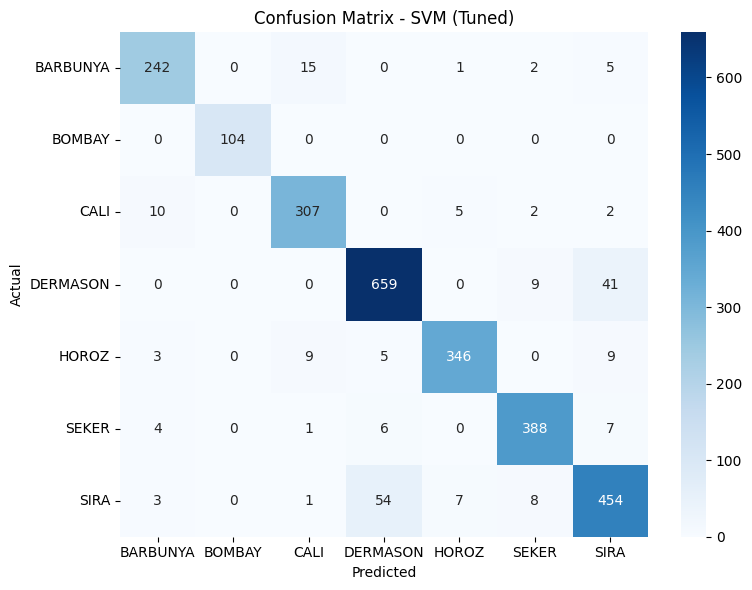

In [35]:
evaluate(best_model, best_name)

**Best model: SVM (Tuned)** with an RBF kernel, `C=100`, `gamma=0.03`.
- It has the highest cross-validation macro-F1 on the training data (about 0.942) and was therefore selected without looking at the test set.
- Test accuracy **0.9228**, test macro-F1 **0.9339**, train accuracy 0.9426 (gap about 0.02), so it is **not overfitted**.
- Several other models (Voting classifier, tuned Logistic Regression, Random Forest) are within about 0.1 percentage point on the test set, so the differences between the top models are small; SVM is preferred because it is consistently best in cross-validation and does not overfit.
- The per-class report shows BOMBAY, HOROZ and SEKER are classified best, and SIRA is the hardest class.

## Task 10: Simple Classifier App (Streamlit)

The final model, the scaler, the label encoder and the preprocessing information (IQR bounds, skew-transform settings, feature ranges) are saved with `joblib`. The Streamlit app loads them, takes the 16 bean measurements as input, applies **exactly the same preprocessing as in training** (capping → skew transforms → scaling) and shows the predicted bean type.

### 10.1 Save the model and preprocessing objects

In [36]:
artifacts = {
    'model': best_model, 'scaler': scaler, 'label_encoder': le,
    'features': features, 'bounds': bounds, 'right_skew': right_skew,
    'median': df[features].median().to_dict(),
    'class_means': df.groupby('Class')[features].mean().to_dict('index'),
    'min': df[features].min().to_dict(), 'max': df[features].max().to_dict(),
}
joblib.dump(artifacts, 'bean_model.joblib')
print('Saved bean_model.joblib | final model:', best_name)

Saved bean_model.joblib | final model: SVM (Tuned)


### 10.2 Test the prediction pipeline inside the notebook

Raw measurements of unseen test beans go through the same steps the app uses.

In [37]:
def predict_bean(measurements):
    x = pd.DataFrame([measurements])[features]
    for c in features:
        x[c] = x[c].clip(*bounds[c])
    x = fix_skew(x)
    xs = scaler.transform(x)
    return le.inverse_transform(best_model.predict(xs))[0]

demo = df.loc[X_test.index].groupby('Class').head(2)
demo_out = pd.DataFrame({'Actual': demo['Class'].values,
                         'Predicted': [predict_bean(r[features].to_dict()) for _, r in demo.iterrows()]})
demo_out['Correct'] = demo_out['Actual'] == demo_out['Predicted']
demo_out

,Actual,Predicted,Correct
0,SEKER,SEKER,True
1,DERMASON,DERMASON,True
2,DERMASON,DERMASON,True
3,HOROZ,HOROZ,True
4,SEKER,SEKER,True
5,BARBUNYA,BARBUNYA,True
6,SIRA,SIRA,True
7,HOROZ,HOROZ,True
8,SIRA,SIRA,True
9,BOMBAY,BOMBAY,True


### 10.3 Streamlit app code

The next cell writes `app.py` (the app file) into the working folder.

In [40]:
import joblib
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Dry Bean Classifier", layout="wide")

@st.cache_resource
def load_artifacts():
    return joblib.load("bean_model.joblib")

art = load_artifacts()

model = art["model"]
scaler = art["scaler"]
le = art["label_encoder"]

features = art["features"]
bounds = art["bounds"]
right_skew = art["right_skew"]

def fix_skew(data):
    data = data.copy()

    for c in right_skew:
        data[c] = np.log1p(data[c])

    for c in ["Eccentricity", "Extent"]:
        data[c] = data[c] ** 3

    for c in ["Solidity", "ShapeFactor4"]:
        data[c] = -np.log(1.001 - data[c].clip(upper=1.0))

    return data

st.title("Dry Bean Type Classifier")

st.write("Enter the physical measurements of a bean to predict its type.")

example = st.selectbox(
    "Start from an example bean",
    ["Dataset median"] + list(le.classes_)
)

if example == "Dataset median":
    defaults = art["median"]
else:
    defaults = art["class_means"][example]

st.subheader("Bean Measurements")

cols = st.columns(4)
values = {}

for i, f in enumerate(features):
    lo = float(art["min"][f])
    hi = float(art["max"][f])

    with cols[i % 4]:
        values[f] = st.number_input(
            f,
            min_value=lo,
            max_value=hi,
            value=float(defaults[f]),
            step=(hi - lo) / 200,
            format="%.6f",
            key=f"{f}_{example}"
        )

if st.button("Predict Bean Type", type="primary"):

    x = pd.DataFrame([values])[features]

    for c in features:
        x[c] = x[c].clip(*bounds[c])

    x = fix_skew(x)
    xs = scaler.transform(x)

    label = le.inverse_transform(model.predict(xs))[0]

    st.success(f"Predicted Bean Type: {label}")

    if hasattr(model, "predict_proba"):
        proba = pd.Series(
            model.predict_proba(xs)[0],
            index=le.classes_
        ).sort_values(ascending=False)

        st.caption(f"Confidence: {proba.iloc[0] * 100:.1f}%")
        st.bar_chart(proba)

2026-11-06 10:04:07.679 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 10:04:07.686 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 10:04:07.698 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 10:04:07.960 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-06 10:04:07.962 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 10:04:07.963 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 10:04:07.964 Thread 'MainThread'

## Conclusion

- A complete machine-learning pipeline was built to classify seven dry-bean types from 16 physical measurements: cleaning (68 duplicates removed), outlier capping, skewness treatment, stratified split and scaling.
- Eleven classifiers were compared with cross-validation, class-imbalance techniques were tested, and the top models were tuned. The final model, an **SVM with RBF kernel, reaches 92.3% test accuracy and a macro-F1 of 0.934** without overfitting.
- BOMBAY beans are identified perfectly; the remaining errors are mostly between SIRA and DERMASON and between BARBUNYA and CALI, whose measurements genuinely overlap.
- Class imbalance did not hurt performance, and hyper-parameter tuning gave only marginal gains, so the model is limited mainly by the information in the features.
- **Business impact:** the company can replace manual sorting with an automatic classifier that is right in about 9 of 10 cases, and the Streamlit app shows how it can be used for real-time prediction from camera measurements.
- **Possible improvements:** remove redundant correlated features, add new image features, or try stacking ensembles.